# Dog Pain Database Prep

Prepare a leakage-aware text/tabular OpenFARM dataset from the public Zenodo Dog Pain Database.

Goals:

- download and verify the Zenodo Excel source
- inspect raw sheets/columns before committing to labels
- normalize row-level metadata
- build dog-heldout train/test splits
- render AWW-style canine pain examples without exposing target columns in prompts
- optionally push a prepared Hugging Face dataset

Source: https://zenodo.org/records/15303646


In [1]:
#@title Setup dependencies and imports
!pip -q install datasets huggingface_hub openpyxl scikit-learn

import hashlib
import json
import os
import random
import re
import textwrap
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests
from datasets import Dataset, DatasetDict
from huggingface_hub import HfApi, login
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
random.seed(SEED)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 180)


In [2]:
#@title Configuration
RECORD_ID = "15303646"
SOURCE_FILE = "Dog pain database.xlsx"
ZENODO_API_URL = f"https://zenodo.org/api/records/{RECORD_ID}"
ZENODO_RECORD_URL = f"https://zenodo.org/records/{RECORD_ID}"
EXPECTED_MD5 = "adbd7322712a3c99d7b7f9e972126a0b"

WORK_DIR = Path(os.environ.get(
    "OPENFARM_DOG_PAIN_WORK_DIR",
    "/content/openfarm_dog_pain" if Path("/content").exists() else "dog_pain_work",
))
RAW_DIR = WORK_DIR / "raw"
OUT_DIR = WORK_DIR / "prepared"
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

HF_REPO_ID = "oliveirabruno01/openfarm-dog-pain"  #@param {type:"string"}
PUSH_TO_HUB = True  #@param {type:"boolean"}
PRIVATE_REPO = False  #@param {type:"boolean"}

# Split policy knobs, not scientific constants.
# TEST_DOG_TARGET chooses roughly how many held-out dogs we want; the actual row ratio is audited later.
TEST_DOG_TARGET = 35  #@param {type:"integer"}
TEST_SIZE_FALLBACK = 0.20  #@param {type:"number"}

# Prompt budgets are audited in the prompt-rendering cell.
# Leave as None to use adaptive values from data quantiles.
MAX_FIELD_CHARS = None  #@param {type:"raw"}
MAX_PROMPT_CHARS = None  #@param {type:"raw"}
FIELD_CHAR_QUANTILE = 0.95  #@param {type:"number"}
PROMPT_CHAR_QUANTILE = 0.99  #@param {type:"number"}
FIELD_CHAR_FLOOR = 700  #@param {type:"integer"}
FIELD_CHAR_CEILING = 1600  #@param {type:"integer"}
PROMPT_CHAR_FLOOR = 3500  #@param {type:"integer"}
PROMPT_CHAR_CEILING = 7000  #@param {type:"integer"}

# Optional prompt variants. Keep surgery/recovery fields off by default because their missingness is label-correlated.
INCLUDE_EXTENDED_SURGERY_FIELDS = False  #@param {type:"boolean"}

print("work dir:", WORK_DIR)
print("outputs:", OUT_DIR)

work dir: /content/openfarm_dog_pain
outputs: /content/openfarm_dog_pain/prepared


In [3]:
#@title Download and verify Zenodo source

def file_md5(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.md5()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

record = requests.get(ZENODO_API_URL, timeout=60).json()
record["metadata"]["title"], record["metadata"].get("doi"), record["metadata"].get("license")

source_item = next(item for item in record["files"] if item["key"] == SOURCE_FILE)
source_path = RAW_DIR / SOURCE_FILE
expected_size = int(source_item["size"])
expected_md5 = source_item["checksum"].split(":", 1)[1]
assert expected_md5 == EXPECTED_MD5, (expected_md5, EXPECTED_MD5)

if not source_path.exists() or source_path.stat().st_size != expected_size or file_md5(source_path) != expected_md5:
    print(f"Downloading {SOURCE_FILE} ({expected_size / 1024:.1f} KiB)")
    with requests.get(source_item["links"]["self"], stream=True, timeout=(60, 300)) as r:
        r.raise_for_status()
        tmp = source_path.with_suffix(source_path.suffix + ".part")
        with tmp.open("wb") as f:
            for chunk in r.iter_content(1024 * 1024):
                if chunk:
                    f.write(chunk)
        tmp.rename(source_path)

assert source_path.stat().st_size == expected_size
assert file_md5(source_path) == expected_md5
print("verified:", source_path, source_path.stat().st_size, file_md5(source_path))


verified: /content/openfarm_dog_pain/raw/Dog pain database.xlsx 251795 adbd7322712a3c99d7b7f9e972126a0b


In [4]:
#@title Load workbook and inspect raw sheets
sheets = pd.read_excel(source_path, sheet_name=None, engine="openpyxl")
for sheet_name, frame in sheets.items():
    nonempty = frame.dropna(how="all")
    print(sheet_name, frame.shape, "non-empty rows:", len(nonempty))

sheet_name, raw_df = max(sheets.items(), key=lambda item: item[1].dropna(how="all").shape[0])
print("selected sheet:", sheet_name)
display(raw_df.head(3))
print("raw columns:")
for i, col in enumerate(raw_df.columns):
    print(f"{i:02d}", repr(col))


Tabelle1 (594, 77) non-empty rows: 594
selected sheet: Tabelle1


,Dog ID Database,Number of observation,Breed,Weight,Birth date,Sex,Neuter status,Type of patient,Primary diagnosis,Medical history,"Medication administered (type, dosis, time)","Anaesthesia for surgery (medication administred, start time, anaesthesia time)",Orthopedic examination (Polypoint),Neurologic examination (Polypoint),Type of patient.1,Situation,Time since end of surgery,Fully recovered from aneatesia,Pain type,Pain origin,Duration of pain,Estimated severity,GCPS: Look at dog in kennel/examination room: Is the dog (1)?,GCPS: Look at dog in kennel/examination room: Is the dog (2)?,Put lead on dog and walk animal out of the kennel: When the dog rises/walks: Is it?,"If the dog has a wound or painful area including abdomen, apply gentle pressure 2 inches (5 cm) around the site. Does it?",9-Overall: Is the dog (1)?,9-Overall: Is the dog (2)?,Monash personality questionnaire,[freundlich],[ausdauernd],[nervös],[energiegeladen],[aufmerksam],[umgänglich],[unabhängig],[trainerbar],[nicht aggressiv],[hyperaktiv],[unterwürfig],[entschlossen],[entspannt],[hartnäckig],[schüchtern],"[folgsam (wie bereitwillig ist der Hund, das zu tun, was von ihm verlangt wird?)]",[aktiv],[intelligent],[gesellig],[unruhig],[ängstlich],[gehorsam],[lebhaft],[zuverlässig],[durchsetzungsfähig],[erregbar],PANAS questionnaire,[1. Ihr Hund ist selten ängstlich],"[2. Ihr Hund wird sehr aufgeregt, wenn er kurz davor ist, spazieren zu gehen (z.B. wenn er seine Leine sieht oder ""Gassi"" hört, etc.)]",[3. Ihr Hund erschrickt schnell durch Geräusche und/oder Bewegungen],"[4. Ihr Hund ist sehr hartnäckig in seinen Bemühungen, Sie zum Spielen zu bewegen]",[5. Ihr Hund zeigt wenig Interesse an seiner Umgebung],"[6. Ihr Hund wirkt nervös und/oder schreckhaft noch für mehrere Minuten, nachdem er erschreckt wurde]",[7. Ihr Hund ist leicht erregbar],[8. Ihr Hund hat eine spezifische Angst oder Phobie],"[9. Ihr Hund versucht, aus dem Garten zu entkommen]","[10. Ihr Hund wirkt ruhig an lauten, überfüllten Orten]",[11. Ihr Hund ist voller Energie],[12. Ihr Hund hat Angst vor Geräuschen aus dem Fernseher oder Radio],[13. Ihr Hund wirkt normalerweise entspannt],[14. Ihr Hund ist faul],"[15. Ihr Hund passt sich schnell an Veränderungen in seiner Umgebung an (z.B. wenn er von verschiedenen Personen betreut wird, umzieht oder ein Familienmitglied das Haus verlässt).]",[16. Ihr Hund scheint Angst vor dem Staubsauger oder einem anderen bekannten Haushaltsgerät zu haben],"[17. Ihr Hund benötigt viel Ermutigung, um an energiegeladenen Aktivitäten teilzunehmen]",[18. Ihr Hund bleibt trotz Zurechtweisung für sein Verhalten ungezogen],[19. Ihr Hund wirkt ruhig in unbekannten Umgebungen],[20. Ihr Hund ist sehr ungestüm.],"[21. Ihr Hund wirkt beunruhigt durch Veränderungen in seiner Routine (z.B. wenn er nicht zur gewohnten Zeit gefüttert wird, wenn er länger als gewöhnlich allein gelassen wird)]"
0,1,1,Bernese Mountain Dog,32.9 kg & 41.7 kg,2023-07-19 00:00:00,f,not neutered,NaN,"Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right ab...","Back pain and stiff gait since a month, after a few weeks start lameness of the right hind leg. Multiple Dexamethason injections and Onsior treatment but the symptoms continue ...","Gabapentin 10 mg/kg PO TID, Marbofloxacine 4 mg/kg IV SID, Metacam 0.1 mg/kg IV SID, Buprenorphine 0.015 mg/kg IV TID, Ondansetron 0.3 mg/kg IV TID, (Augensalbe bds q4h, RA 2 ...","Intervention on 12.08: CT and exploratory laparatomy with ovariohysterectomy. Premedication at 10:10: Acepromazin 0.005 mg/kg IM, Medetomidin 0.01 mg/kg IM, Methadon 0.3 mg/kg ...",NaN,"Done a week before. Mentation: normal. Posture: no weight bearing of the right hind limb, nerve root sign, often puts the leg underneath the body. Gait: lameness right hind lim...","Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cav

raw columns:
00 'Dog ID Database'
01 'Number of observation'
02 'Breed'
03 'Weight'
04 'Birth date'
05 'Sex'
06 'Neuter status'
07 'Type of patient'
08 'Primary diagnosis'
09 'Medical history'
10 'Medication administered (type, dosis, time)'
11 'Anaesthesia for surgery (medication administred, start time, anaesthesia time)'
12 'Orthopedic examination (Polypoint)'
13 'Neurologic examination (Polypoint)'
14 'Type of patient.1'
15 'Situation'
16 'Time since end of surgery'
17 'Fully recovered from aneatesia'
18 'Pain type'
19 'Pain origin'
20 'Duration of pain'
21 'Estimated severity'
22 'GCPS: Look at dog in kennel/examination room: Is the dog (1)?'
23 'GCPS: Look at dog in kennel/examination room: Is the dog (2)?'
24 'Put lead on dog and walk animal out of the kennel: When the dog rises/walks: Is it?'
25 'If the dog has a wound or painful area including abdomen, apply gentle pressure 2 inches (5 cm) around the site.\xa0 Does it?'
26 '9-Overall: Is the dog (1)?'
27 '9-Overall: Is the dog

In [5]:
#@title Normalize columns and construct row-level metadata

def norm(value) -> str:
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()


def slug(value) -> str:
    text = norm(value).lower()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return text.strip("_") or "unknown"


def flatten_columns(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.dropna(axis=0, how="all").dropna(axis=1, how="all").copy()
    frame.columns = [slug(col) for col in frame.columns]
    frame = frame.loc[:, ~frame.columns.duplicated()].reset_index(drop=True)
    return frame


def find_col(frame: pd.DataFrame, *needles: str) -> str | None:
    for col in frame.columns:
        hay = col.lower()
        if all(needle in hay for needle in needles):
            return col
    return None


def no_pain_label(text: str) -> bool:
    text = text.lower().strip()
    return text in {"no pain", "no", "without pain"} or "no pain" in text


def pain_bucket(value) -> str:
    text = norm(value).lower()
    if not text:
        return "Unlabeled"
    if no_pain_label(text):
        return "No_Pain"
    if any(term in text for term in ["acute", "postoperative", "surgical", "trauma"]):
        return "Acute_Pain"
    if any(term in text for term in ["chronic", "osteoarthritis", "degenerative"]):
        return "Chronic_Pain"
    if "neuropathic" in text:
        return "Neuropathic_Pain"
    if "visceral" in text:
        return "Visceral_Pain"
    return "Pain"


def aww_from_pain_type(value) -> str:
    text = norm(value)
    if not text:
        return "Unlabeled"
    if no_pain_label(text):
        return "Neutral_Resting"
    return "Negative_Nociceptive"

flat_df = flatten_columns(raw_df)

def exact_col(frame: pd.DataFrame, name: str) -> str | None:
    return name if name in frame.columns else None


COLS = {
    "dog_id": exact_col(flat_df, "dog_id_database") or find_col(flat_df, "dog", "id") or find_col(flat_df, "id") or flat_df.columns[0],
    "observation": exact_col(flat_df, "number_of_observation") or find_col(flat_df, "number", "observation"),
    "breed": exact_col(flat_df, "breed") or find_col(flat_df, "breed"),
    "weight": exact_col(flat_df, "weight") or find_col(flat_df, "weight"),
    "birth_date": exact_col(flat_df, "birth_date") or find_col(flat_df, "birth", "date"),
    "sex": exact_col(flat_df, "sex") or find_col(flat_df, "sex"),
    "neuter_status": exact_col(flat_df, "neuter_status") or find_col(flat_df, "neuter"),
    "patient_type": exact_col(flat_df, "type_of_patient_1") or exact_col(flat_df, "type_of_patient") or find_col(flat_df, "type", "patient"),
    "primary_diagnosis": exact_col(flat_df, "primary_diagnosis") or find_col(flat_df, "primary", "diagnosis"),
    "medical_history": exact_col(flat_df, "medical_history") or find_col(flat_df, "medical", "history"),
    "medication": exact_col(flat_df, "medication_administered_type_dosis_time") or find_col(flat_df, "medication", "administered"),
    "anesthesia": exact_col(flat_df, "anaesthesia_for_surgery_medication_administred_start_time_anaesthesia_time") or find_col(flat_df, "anaesthesia") or find_col(flat_df, "anesthesia"),
    "orthopedic_exam": exact_col(flat_df, "orthopedic_examination_polypoint") or find_col(flat_df, "orthopedic", "examination"),
    "neurologic_exam": exact_col(flat_df, "neurologic_examination_polypoint") or find_col(flat_df, "neurologic", "examination"),
    "situation": exact_col(flat_df, "situation") or find_col(flat_df, "situation"),
    "time_since_surgery": exact_col(flat_df, "time_since_end_of_surgery") or find_col(flat_df, "time", "since", "surgery"),
    "recovered_anesthesia": exact_col(flat_df, "fully_recovered_from_aneatesia") or find_col(flat_df, "recovered"),
    "pain_type": exact_col(flat_df, "pain_type") or find_col(flat_df, "pain", "type"),
    "pain_origin": exact_col(flat_df, "pain_origin") or find_col(flat_df, "pain", "origin"),
    "pain_duration": exact_col(flat_df, "duration_of_pain") or find_col(flat_df, "duration", "pain"),
    "estimated_severity": exact_col(flat_df, "estimated_severity") or find_col(flat_df, "estimated", "severity"),
}

print(json.dumps(COLS, indent=2))

rows = []
for idx, row in flat_df.iterrows():
    item = {
        "source_subject_id": norm(row.get(COLS["dog_id"])),
        "source_observation_id": norm(row.get(COLS["observation"])),
        "source_row_index": idx + 1,
        "species": "dog",
        "breed": norm(row.get(COLS["breed"])),
        "weight": norm(row.get(COLS["weight"])),
        "birth_date": norm(row.get(COLS["birth_date"])),
        "sex": norm(row.get(COLS["sex"])),
        "neuter_status": norm(row.get(COLS["neuter_status"])),
        "patient_type": norm(row.get(COLS["patient_type"])),
        "primary_diagnosis": norm(row.get(COLS["primary_diagnosis"])),
        "medical_history": norm(row.get(COLS["medical_history"])),
        "medication": norm(row.get(COLS["medication"])),
        "anesthesia": norm(row.get(COLS["anesthesia"])),
        "orthopedic_exam": norm(row.get(COLS["orthopedic_exam"])),
        "neurologic_exam": norm(row.get(COLS["neurologic_exam"])),
        "situation": norm(row.get(COLS["situation"])),
        "time_since_surgery": norm(row.get(COLS["time_since_surgery"])),
        "recovered_anesthesia": norm(row.get(COLS["recovered_anesthesia"])),
        "pain_type": norm(row.get(COLS["pain_type"])),
        "pain_origin": norm(row.get(COLS["pain_origin"])),
        "pain_duration": norm(row.get(COLS["pain_duration"])),
        "estimated_severity": norm(row.get(COLS["estimated_severity"])),
    }
    item["pain_bucket"] = pain_bucket(item["pain_type"])
    item["aww_category"] = aww_from_pain_type(item["pain_type"])
    item["pain_binary"] = "no_pain" if item["aww_category"] == "Neutral_Resting" else "pain" if item["aww_category"] == "Negative_Nociceptive" else "unlabeled"
    item["label_status"] = "explicit_pain_type" if item["pain_type"] else "missing_pain_type"
    rows.append(item)

metadata_df = pd.DataFrame(rows)
metadata_path = OUT_DIR / "dog_pain_metadata.csv"
metadata_df.to_csv(metadata_path, index=False)
print(metadata_df.shape)
display(metadata_df.head(5))


{
  "dog_id": "dog_id_database",
  "observation": "number_of_observation",
  "breed": "breed",
  "weight": "weight",
  "birth_date": "birth_date",
  "sex": "sex",
  "neuter_status": "neuter_status",
  "patient_type": "type_of_patient_1",
  "primary_diagnosis": "primary_diagnosis",
  "medical_history": "medical_history",
  "medication": "medication_administered_type_dosis_time",
  "anesthesia": "anaesthesia_for_surgery_medication_administred_start_time_anaesthesia_time",
  "orthopedic_exam": "orthopedic_examination_polypoint",
  "neurologic_exam": "neurologic_examination_polypoint",
  "situation": "situation",
  "time_since_surgery": "time_since_end_of_surgery",
  "recovered_anesthesia": "fully_recovered_from_aneatesia",
  "pain_type": "pain_type",
  "pain_origin": "pain_origin",
  "pain_duration": "duration_of_pain",
  "estimated_severity": "estimated_severity"
}
(594, 27)


,source_subject_id,source_observation_id,source_row_index,species,breed,weight,birth_date,sex,neuter_status,patient_type,primary_diagnosis,medical_history,medication,anesthesia,orthopedic_exam,neurologic_exam,situation,time_since_surgery,recovered_anesthesia,pain_type,pain_origin,pain_duration,estimated_severity,pain_bucket,aww_category,pain_binary,label_status
0,1,1,1,dog,Bernese Mountain Dog,32.9 kg & 41.7 kg,2023-07-19 00:00:00,f,not neutered,"Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right ab...","Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right ab...","Back pain and stiff gait since a month, after a few weeks start lameness of the right hind leg. Multiple Dexamethason injections and Onsior treatment but the symptoms continue ...","Gabapentin 10 mg/kg PO TID, Marbofloxacine 4 mg/kg IV SID, Metacam 0.1 mg/kg IV SID, Buprenorphine 0.015 mg/kg IV TID, Ondansetron 0.3 mg/kg IV TID, (Augensalbe bds q4h, RA 2 m...","Intervention on 12.08: CT and exploratory laparatomy with ovariohysterectomy. Premedication at 10:10: Acepromazin 0.005 mg/kg IM, Medetomidin 0.01 mg/kg IM, Methadon 0.3 mg/kg ...",,"Done a week before. Mentation: normal. Posture: no weight bearing of the right hind limb, nerve root sign, often puts the leg underneath the body. Gait: lameness right hind lim...","Hospitalized, elective surgery",,,"acute, somatic","back, hind legs, Pelvic musculature right",more than 7 days,60,Acute_Pain,Negative_Nociceptive,pain,explicit_pain_type
1,1,2,2,dog,Bernese Mountain Dog,32.9 kg & 41.7 kg,2023-07-20 00:00:00,f,not neutered,"Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right ab...","Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right ab...","Back pain and stiff gait since a month, after a few weeks start lameness of the right hind leg. Multiple Dexamethason injections and Onsior treatment but the symptoms continue ...","Gabapentin 10 mg/kg PO TID, Marbofloxacine 4 mg/kg IV SID, Metacam 0.1 mg/kg IV SID, Buprenorphine 0.015 mg/kg IV TID, Ondansetron 0.3 mg/kg IV TID, (Augensalbe bds q4h, RA 2 m...","Intervention on 12.08: CT and exploratory laparatomy with ovariohysterectomy. Premedication at 10:10: Acepromazin 0.005 mg/kg IM, Medetomidin 0.01 mg/kg IM, Methadon 0.3 mg/kg ...",,"Done a week before. Mentation: normal. Posture: no weight bearing of the right hind limb, nerve root sign, often puts the leg underneath the body. Gait: lameness right hind lim...",,,,,,,,Unlabeled,Unlabeled,unlabeled,missing_pain_type
2,1,3,3,dog,Bernese Mountain Dog,32.9 kg & 41.7 kg,2023-07-21 00:00:00,f,not neutered,"Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right ab...","Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right ab...","Back pain and stiff gait since a month, after a few weeks start lameness of the right hind leg. Multiple Dexamethason injections and Onsior treatment but the symptoms continue ...","Gabapentin 10 mg/kg PO TID, Marbofloxacine 4 mg/kg IV SID, Metacam 0.1 mg/kg IV SID, Buprenorphine 0.015 mg/kg IV TID, Ondansetron 0.3 mg/kg IV TID, (Augensalbe bds q4h, RA 2 m...","Intervention on 12.08: CT and exploratory laparatomy with ovariohysterectomy. Premedication at 10:10: Acepromazin 0.005 mg/kg IM, Medetomidin 0.01 mg/kg IM, Methadon 0.3 mg/kg ...",,"Done a week before. Mentation: normal. Posture: no we

In [6]:
#@title Dataset audit and label distributions

def count_dict(series):
    return dict(Counter([x if norm(x) else "<missing>" for x in series]))

audit = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "source_url": ZENODO_RECORD_URL,
    "doi": record["metadata"].get("doi"),
    "license": record["metadata"].get("license", {}).get("id"),
    "rows": int(len(metadata_df)),
    "unique_dogs": int(metadata_df["source_subject_id"].nunique()),
    "selected_columns": COLS,
    "distributions": {
        "aww_category": count_dict(metadata_df["aww_category"]),
        "pain_binary": count_dict(metadata_df["pain_binary"]),
        "pain_bucket": count_dict(metadata_df["pain_bucket"]),
        "label_status": count_dict(metadata_df["label_status"]),
        "sex": count_dict(metadata_df["sex"]),
        "breed_top20": dict(Counter(metadata_df["breed"]).most_common(20)),
    },
    "split_policy": {
        "test_dog_target": TEST_DOG_TARGET,
        "test_size_fallback": TEST_SIZE_FALLBACK,
        "rationale": "Dog-heldout evaluation with enough held-out subjects for stable per-class metrics; exact row ratio is audited after split.",
    },
    "prompt_budget_policy": {
        "max_field_chars": MAX_FIELD_CHARS,
        "max_prompt_chars": MAX_PROMPT_CHARS,
        "field_char_quantile": FIELD_CHAR_QUANTILE,
        "prompt_char_quantile": PROMPT_CHAR_QUANTILE,
        "rationale": "Default values are derived from source-text length quantiles and bounded for model context budget.",
    },
    "leakage_policy": {
        "never_prompt": ["pain_type", "pain_bucket", "aww_category", "pain_binary", "label_status", "estimated_severity"],
        "prompt_by_default": ["species", "breed", "sex", "neuter_status", "patient_type", "primary_diagnosis", "medical_history", "situation", "time_since_surgery", "recovered_anesthesia"],
        "review_before_prompting": ["medication", "anesthesia", "orthopedic_exam", "neurologic_exam", "pain_origin", "pain_duration"],
    },
}

with (OUT_DIR / "dataset_audit.json").open("w") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)

print(json.dumps(audit["distributions"], indent=2, ensure_ascii=False))
assert audit["license"] == "cc-by-4.0", audit["license"]


{
  "aww_category": {
    "Negative_Nociceptive": 514,
    "Unlabeled": 37,
    "Neutral_Resting": 43
  },
  "pain_binary": {
    "pain": 514,
    "unlabeled": 37,
    "no_pain": 43
  },
  "pain_bucket": {
    "Acute_Pain": 447,
    "Unlabeled": 37,
    "No_Pain": 43,
    "Chronic_Pain": 55,
    "Pain": 8,
    "Visceral_Pain": 3,
    "Neuropathic_Pain": 1
  },
  "label_status": {
    "explicit_pain_type": 557,
    "missing_pain_type": 37
  },
  "sex": {
    "f": 291,
    "m": 240,
    "male": 36,
    "female": 27
  },
  "breed_top20": {
    "Crossbreed": 81,
    "Labrador Retriever": 46,
    "French Bulldog": 35,
    "Yorkshire Terrier": 32,
    "Australian Sheperd": 18,
    "Flat Coated Retriever": 15,
    "Pomeranian": 15,
    "Boxer": 14,
    "Miniature Poodle": 12,
    "crossbreed": 12,
    "Bernese Mountain Dog": 11,
    "Jack Russell Terrier": 10,
    "Beagle": 10,
    "Dachshund": 9,
    "German Sheperd": 9,
    "Newfoundlander": 8,
    "Bolonka Zwetna": 8,
    "American Bulldog

In [7]:
#@title Define leakage-safe prompt rendering + adaptive budget audit
# Target/leaky fields are kept in metadata for scoring and analysis, but never inserted into prompts.
# This is a clinical text-triage prompt, not a subtle visual pain-recognition prompt.

CORE_PROMPT_FIELDS = [
    ("Species", "species"),
    ("Breed", "breed"),
    ("Sex", "sex"),
    ("Neuter status", "neuter_status"),
    ("Primary diagnosis", "primary_diagnosis"),
    ("Medical history", "medical_history"),
    ("Clinical situation", "situation"),
]

EXTENDED_SURGERY_FIELDS = [
    ("Time since end of surgery", "time_since_surgery"),
    ("Fully recovered from anesthesia", "recovered_anesthesia"),
]

SAFE_PROMPT_FIELDS = CORE_PROMPT_FIELDS + (EXTENDED_SURGERY_FIELDS if INCLUDE_EXTENDED_SURGERY_FIELDS else [])

TARGET_OR_LEAKY_FIELDS = {
    "pain_type",
    "pain_bucket",
    "aww_category",
    "pain_binary",
    "label_status",
    "estimated_severity",
    "pain_origin",
    "pain_duration",
}

eligible_df = metadata_df[
    metadata_df["aww_category"].isin(["Negative_Nociceptive", "Neutral_Resting"])
].copy()
print("eligible rows:", len(eligible_df), "dogs:", eligible_df["source_subject_id"].nunique())
print("prompt fields:", [label for label, _ in SAFE_PROMPT_FIELDS])


def optional_int(value):
    if value is None:
        return None
    if isinstance(value, str) and value.strip().lower() in {"", "none", "null"}:
        return None
    return int(value)


def clamp(value: int, floor: int, ceiling: int) -> int:
    return max(floor, min(ceiling, int(value)))


def raw_case_text(row: pd.Series) -> str:
    lines = []
    for label, col in SAFE_PROMPT_FIELDS:
        assert col not in TARGET_OR_LEAKY_FIELDS, col
        value = norm(row.get(col, ""))
        if value:
            lines.append(f"- {label}: {value}")
    return "\n".join(lines)


configured_field_chars = optional_int(MAX_FIELD_CHARS)
configured_prompt_chars = optional_int(MAX_PROMPT_CHARS)

field_lengths = []
for _, row in eligible_df.iterrows():
    for _, col in SAFE_PROMPT_FIELDS:
        value = norm(row.get(col, ""))
        if value:
            field_lengths.append(len(value))

raw_case_lengths = [len(raw_case_text(row)) for _, row in eligible_df.iterrows()]
field_length_stats = pd.Series(field_lengths)
raw_case_length_stats = pd.Series(raw_case_lengths)

adaptive_field_chars = clamp(
    field_length_stats.quantile(FIELD_CHAR_QUANTILE) if len(field_length_stats) else FIELD_CHAR_FLOOR,
    FIELD_CHAR_FLOOR,
    FIELD_CHAR_CEILING,
)
adaptive_prompt_chars = clamp(
    raw_case_length_stats.quantile(PROMPT_CHAR_QUANTILE) if len(raw_case_length_stats) else PROMPT_CHAR_FLOOR,
    PROMPT_CHAR_FLOOR,
    PROMPT_CHAR_CEILING,
)

RESOLVED_MAX_FIELD_CHARS = configured_field_chars if configured_field_chars is not None else adaptive_field_chars
RESOLVED_MAX_PROMPT_CHARS = configured_prompt_chars if configured_prompt_chars is not None else adaptive_prompt_chars

print("field length quantiles:")
display(field_length_stats.describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]))
print("raw case length quantiles:")
display(raw_case_length_stats.describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]))
print("using RESOLVED_MAX_FIELD_CHARS:", RESOLVED_MAX_FIELD_CHARS)
print("using RESOLVED_MAX_PROMPT_CHARS:", RESOLVED_MAX_PROMPT_CHARS)


def truncate_text(text: str, limit: int | None = None) -> str:
    limit = RESOLVED_MAX_FIELD_CHARS if limit is None else int(limit)
    text = norm(text)
    if len(text) <= limit:
        return text
    return text[:limit].rsplit(" ", 1)[0] + " ..."


def render_case(row: pd.Series) -> str:
    """Used strictly for budgeting and leakage auditing. Verifiers envs will handle actual prompt rendering."""
    lines = []
    for label, col in SAFE_PROMPT_FIELDS:
        assert col not in TARGET_OR_LEAKY_FIELDS, col
        value = truncate_text(row.get(col, ""))
        if value:
            lines.append(f"- {label}: {value}")

    case = "\n".join(lines)
    if len(case) > RESOLVED_MAX_PROMPT_CHARS:
        case = case[:RESOLVED_MAX_PROMPT_CHARS].rsplit("\n", 1)[0]
        case += "\n- Note: case text truncated for benchmark length."
    return case

print("\n--- Visual Audit Preview ---")
print(render_case(eligible_df.iloc[0])[:2200])
print("target:", eligible_df.iloc[0]["aww_category"])

eligible rows: 557 dogs: 175
prompt fields: ['Species', 'Breed', 'Sex', 'Neuter status', 'Primary diagnosis', 'Medical history', 'Clinical situation']
field length quantiles:


,0
count,3884.000000
mean,165.011071
std,440.281158
min,1.000000
50%,12.000000
75%,31.000000
90%,621.000000
95%,1169.000000
99%,2185.000000
max,3371.000000


raw case length quantiles:


,0
count,557.000000
mean,1262.032316
std,688.705774
min,160.000000
50%,1080.000000
75%,1675.000000
90%,2329.000000
95%,2537.000000
99%,3181.880000
max,3592.000000


using RESOLVED_MAX_FIELD_CHARS: 1169
using RESOLVED_MAX_PROMPT_CHARS: 3500

--- Visual Audit Preview ---
- Species: dog
- Breed: Bernese Mountain Dog
- Sex: f
- Neuter status: not neutered
- Primary diagnosis: Intrapelvic and subcutaneous abscesses, discospondylitis, left renal pelvic and proximal ureteral dilation, cavitary lesions filled with corpuscular fluid in caudal to right abdomen in close association to the uterus
- Medical history: Back pain and stiff gait since a month, after a few weeks start lameness of the right hind leg. Multiple Dexamethason injections and Onsior treatment but the symptoms continue to come back. After a few weeks + fever and exercise intolerance. Tolfedine injection without improvement of the symptoms -> referal to the clinic on the next day. Pelvic abscesses on MRI. The dog went home after 5 days, came back after 2 days (dysorexia, kyphosis, uncomfortable, blood culture positive). The dog was presented to the Internal Medicine Department on 7 August 20

In [8]:
#@title Build dog-heldout split and balanced eval views
# We first create a natural dog-heldout split, then derive class-balanced train/test views from it.
# Published split names:
# - train/test: balanced views, useful for trainable/eval tasks without majority-class dominance
# - train_raw/test_raw: natural source distribution, useful for prevalence-aware reporting

labels = eligible_df["aww_category"].tolist()
groups = eligible_df["source_subject_id"].tolist()
base_counts = Counter(labels)
base_rate = {k: v / len(labels) for k, v in base_counts.items()}
unique_dog_count = eligible_df["source_subject_id"].nunique()
requested_test_dogs = int(TEST_DOG_TARGET) if TEST_DOG_TARGET else max(1, round(unique_dog_count * TEST_SIZE_FALLBACK))
requested_test_dogs = max(1, min(unique_dog_count - 1, requested_test_dogs))
effective_test_size = requested_test_dogs / unique_dog_count
print("unique supervised dogs:", unique_dog_count)
print("requested held-out dogs:", requested_test_dogs)
print("effective dog-level test size:", round(effective_test_size, 4))

best = None
for seed in range(SEED, SEED + 500):
    splitter = GroupShuffleSplit(n_splits=1, test_size=effective_test_size, random_state=seed)
    train_idx, test_idx = next(splitter.split(eligible_df, labels, groups))
    train_part = eligible_df.iloc[train_idx]
    test_part = eligible_df.iloc[test_idx]
    train_dogs = set(train_part["source_subject_id"])
    test_dogs = set(test_part["source_subject_id"])
    assert train_dogs.isdisjoint(test_dogs)

    test_counts = Counter(test_part["aww_category"])
    test_rate = {k: test_counts.get(k, 0) / len(test_part) for k in base_counts}
    score = sum(abs(test_rate[k] - base_rate[k]) for k in base_counts)
    score += abs(test_part["source_subject_id"].nunique() - requested_test_dogs) / unique_dog_count
    score += abs(len(test_part) / len(eligible_df) - TEST_SIZE_FALLBACK) * 0.25
    candidate = (score, seed, train_part.index.tolist(), test_part.index.tolist())
    if best is None or candidate < best:
        best = candidate

score, split_seed, train_indices, test_indices = best
train_raw_df = eligible_df.loc[train_indices].copy()
test_raw_df = eligible_df.loc[test_indices].copy()
train_raw_df["split"] = "train_raw"
test_raw_df["split"] = "test_raw"
split_df = pd.concat([train_raw_df, test_raw_df], ignore_index=True)


def make_balanced_view(frame: pd.DataFrame, split_name: str, seed: int) -> pd.DataFrame:
    counts = frame["aww_category"].value_counts()
    n = int(counts.min())
    pieces = []
    for label in sorted(counts.index):
        pieces.append(frame[frame["aww_category"] == label].sample(n=n, random_state=seed))
    out = pd.concat(pieces).sample(frac=1, random_state=seed).reset_index(drop=True)
    out["split"] = split_name
    return out

train_df = make_balanced_view(train_raw_df, "train", split_seed)
test_df = make_balanced_view(test_raw_df, "test", split_seed)

print("split seed:", split_seed, "score:", round(score, 4))
print("train_raw rows/dogs:", len(train_raw_df), train_raw_df["source_subject_id"].nunique())
print("test_raw rows/dogs:", len(test_raw_df), test_raw_df["source_subject_id"].nunique())
print("dog overlap:", set(train_raw_df["source_subject_id"]) & set(test_raw_df["source_subject_id"]))
print("train_raw labels:", Counter(train_raw_df["aww_category"]))
print("test_raw labels:", Counter(test_raw_df["aww_category"]))
print("train labels:", Counter(train_df["aww_category"]))
print("test labels:", Counter(test_df["aww_category"]))

split_df.to_csv(OUT_DIR / "dog_pain_split_raw_metadata.csv", index=False)
train_raw_df.to_csv(OUT_DIR / "dog_pain_train_raw_metadata.csv", index=False)
test_raw_df.to_csv(OUT_DIR / "dog_pain_test_raw_metadata.csv", index=False)
train_df.to_csv(OUT_DIR / "dog_pain_train_metadata.csv", index=False)
test_df.to_csv(OUT_DIR / "dog_pain_test_metadata.csv", index=False)

unique supervised dogs: 175
requested held-out dogs: 35
effective dog-level test size: 0.2
split seed: 446 score: 0.0028
train_raw rows/dogs: 441 140
test_raw rows/dogs: 116 35
dog overlap: set()
train_raw labels: Counter({'Negative_Nociceptive': 407, 'Neutral_Resting': 34})
test_raw labels: Counter({'Negative_Nociceptive': 107, 'Neutral_Resting': 9})
train labels: Counter({'Negative_Nociceptive': 34, 'Neutral_Resting': 34})
test labels: Counter({'Negative_Nociceptive': 9, 'Neutral_Resting': 9})


# Dog Pain Visual Diagnostics

These plots are not decorative. Each one should answer a benchmark-design question: balance, leakage, representativeness, missingness, or whether a shallow lexical model can solve the task.


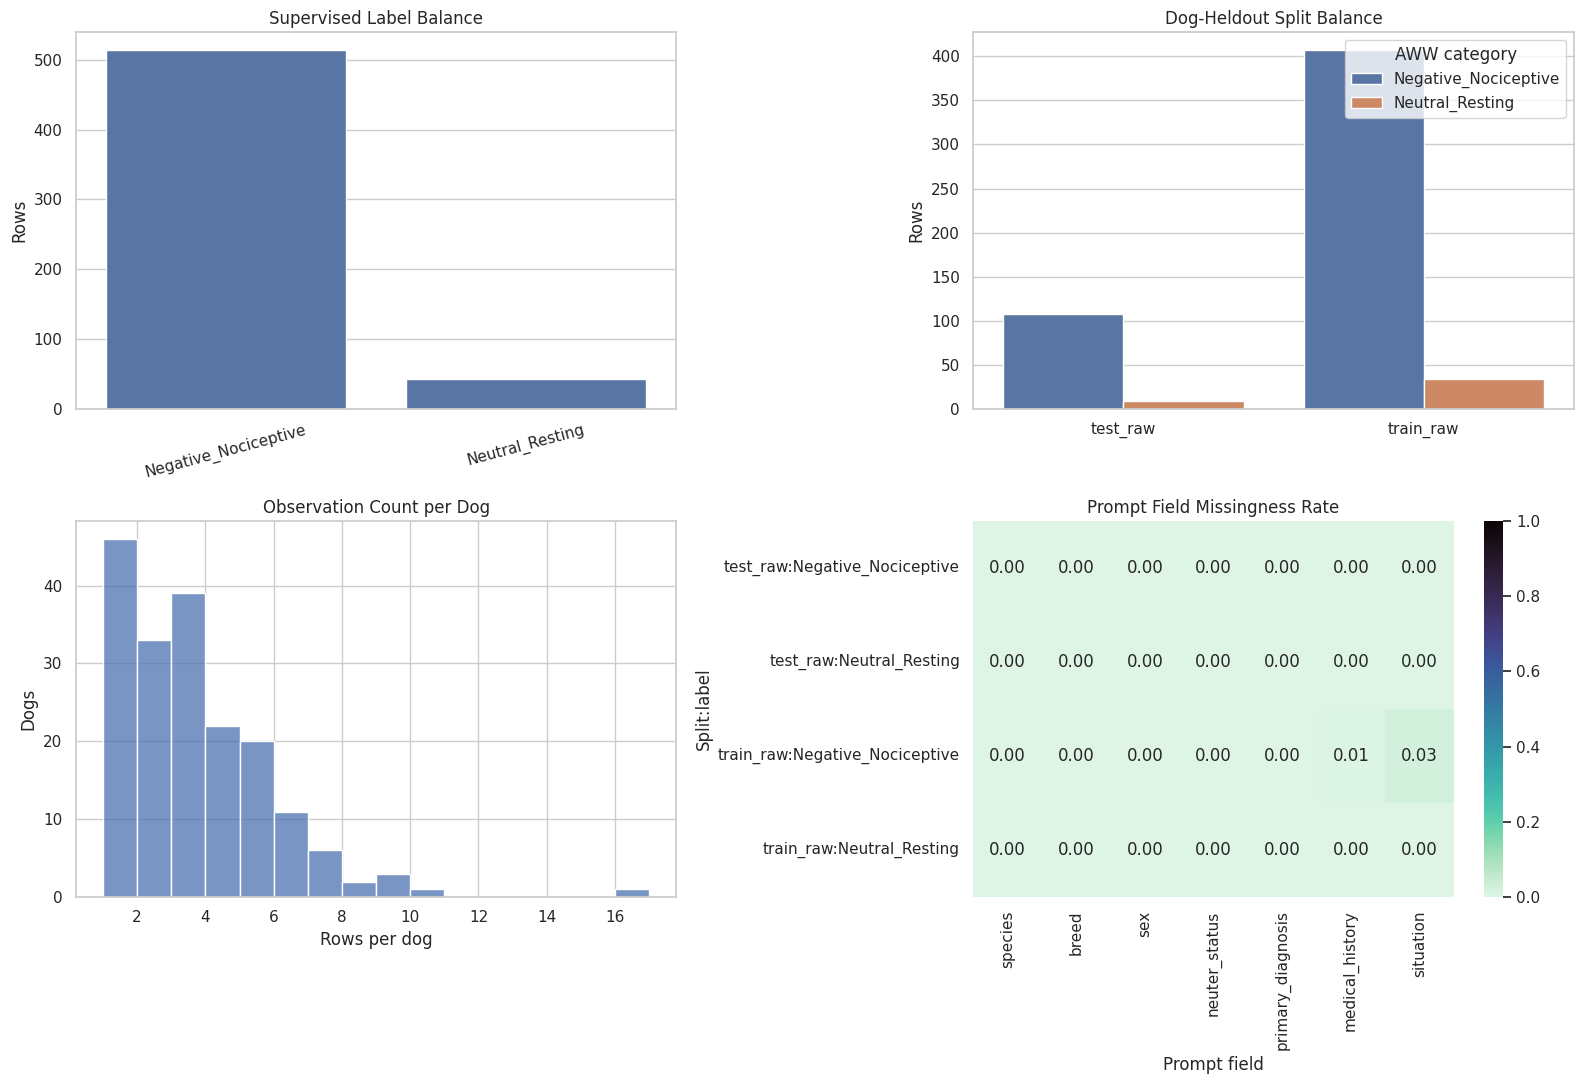

saved: /content/openfarm_dog_pain/prepared/dog_pain_visual_audit.png
Top dogs by number of observations:


,source_subject_id,rows_per_dog
7,105,16
46,140,10
25,121,9
30,126,9
114,25,9
18,115,8
118,3,8
24,120,7
57,151,7
56,150,7


In [9]:
#@title Visual audit: labels, split balance, dog groups, missingness
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plot_df = split_df.copy()
plot_df["prompt_case_chars"] = plot_df.apply(lambda row: len(render_case(row)), axis=1)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Overall supervised label balance.
sns.countplot(data=eligible_df, x="aww_category", order=["Negative_Nociceptive", "Neutral_Resting"], ax=axes[0, 0])
axes[0, 0].set_title("Supervised Label Balance")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Rows")
axes[0, 0].tick_params(axis="x", rotation=15)

# 2. Split x label balance.
split_counts = plot_df.groupby(["split", "aww_category"]).size().reset_index(name="count")
sns.barplot(data=split_counts, x="split", y="count", hue="aww_category", ax=axes[0, 1])
axes[0, 1].set_title("Dog-Heldout Split Balance")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Rows")
axes[0, 1].legend(title="AWW category", loc="upper right")

# 3. Rows per dog: repeated observations can dominate if unchecked.
dog_sizes = metadata_df.groupby("source_subject_id").size().reset_index(name="rows_per_dog")
sns.histplot(dog_sizes["rows_per_dog"], bins=range(1, int(dog_sizes["rows_per_dog"].max()) + 2), ax=axes[1, 0])
axes[1, 0].set_title("Observation Count per Dog")
axes[1, 0].set_xlabel("Rows per dog")
axes[1, 0].set_ylabel("Dogs")

# 4. Missingness in prompt fields by split/label.
fields = [col for _, col in SAFE_PROMPT_FIELDS]
missing = []
for (split, label), group in plot_df.groupby(["split", "aww_category"]):
    row = {"split_label": f"{split}:{label}"}
    for col in fields:
        row[col] = group[col].map(lambda x: not bool(norm(x))).mean()
    missing.append(row)
missing_df = pd.DataFrame(missing).set_index("split_label")
sns.heatmap(missing_df, annot=True, cmap="mako_r", vmin=0, vmax=1, fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("Prompt Field Missingness Rate")
axes[1, 1].set_xlabel("Prompt field")
axes[1, 1].set_ylabel("Split:label")

plt.tight_layout()
fig_path = OUT_DIR / "dog_pain_visual_audit.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", fig_path)

print("Top dogs by number of observations:")
display(dog_sizes.sort_values("rows_per_dog", ascending=False).head(15))


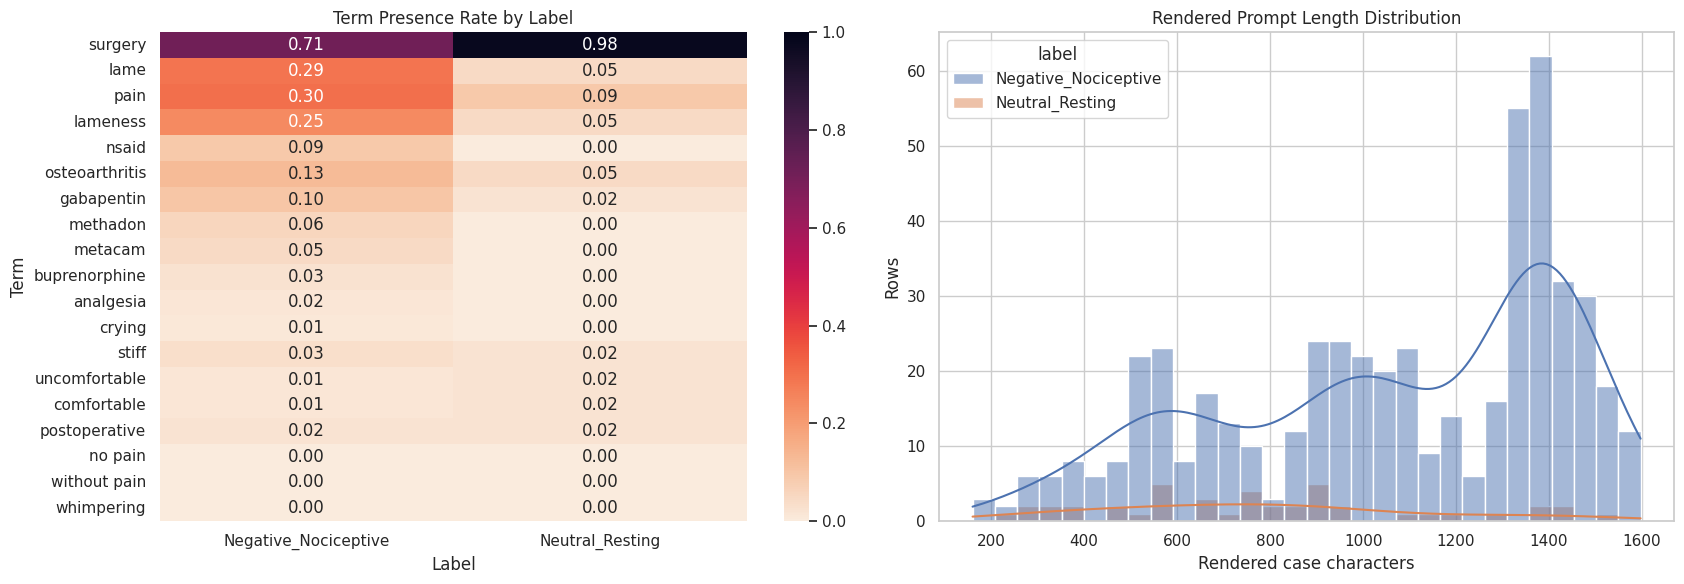

saved: /content/openfarm_dog_pain/prepared/dog_pain_lexical_audit.png
Terms with largest label gaps:


label,Negative_Nociceptive,Neutral_Resting,absolute_gap
surgery,0.714008,0.976744,0.262736
lame,0.289883,0.046512,0.243372
pain,0.303502,0.093023,0.210479
lameness,0.245136,0.046512,0.198625
nsaid,0.093385,0.000000,0.093385
osteoarthritis,0.128405,0.046512,0.081893
gabapentin,0.101167,0.023256,0.077912
methadon,0.056420,0.000000,0.056420
metacam,0.046693,0.000000,0.046693
buprenorphine,0.025292,0.000000,0.025292


In [10]:
#@title Lexical leakage and prompt length audit
# This asks: are labels visible through simple words like pain/lameness/no pain before a model reasons?

LEAKAGE_TERMS = [
    "pain", "no pain", "without pain", "lameness", "lame", "crying", "whimpering",
    "stiff", "uncomfortable", "comfortable", "analgesia", "methadon", "buprenorphine",
    "metacam", "nsaid", "gabapentin", "surgery", "postoperative", "osteoarthritis",
]

lex_rows = []
for _, row in split_df.iterrows():
    text = render_case(row).lower()
    item = {
        "split": row["split"],
        "label": row["aww_category"],
        "prompt_chars": len(text),
    }
    for term in LEAKAGE_TERMS:
        item[term] = int(term in text)
    lex_rows.append(item)

lex_df = pd.DataFrame(lex_rows)
term_rates = lex_df.groupby("label")[LEAKAGE_TERMS].mean().T
term_rates["absolute_gap"] = (term_rates.get("Negative_Nociceptive", 0) - term_rates.get("Neutral_Resting", 0)).abs()
term_rates = term_rates.sort_values("absolute_gap", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(term_rates.drop(columns=["absolute_gap"]).head(20), annot=True, cmap="rocket_r", vmin=0, vmax=1, fmt=".2f", ax=axes[0])
axes[0].set_title("Term Presence Rate by Label")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Term")

sns.histplot(data=lex_df, x="prompt_chars", hue="label", bins=30, kde=True, ax=axes[1])
axes[1].set_title("Rendered Prompt Length Distribution")
axes[1].set_xlabel("Rendered case characters")
axes[1].set_ylabel("Rows")

plt.tight_layout()
fig_path = OUT_DIR / "dog_pain_lexical_audit.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", fig_path)
print("Terms with largest label gaps:")
display(term_rates.head(15))


In [11]:
#@title Shallow lexical baseline check
# If TF-IDF + logistic regression performs very well, the task may be mostly lexical triage rather than deep reasoning.
# We report both the balanced published split and the natural raw split.

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score

LABELS_ORDER = ["Negative_Nociceptive", "Neutral_Resting"]


def run_shallow_baseline(train_frame: pd.DataFrame, test_frame: pd.DataFrame, name: str) -> dict:
    train_texts = [render_case(row) for _, row in train_frame.iterrows()]
    test_texts = [render_case(row) for _, row in test_frame.iterrows()]
    y_train = train_frame["aww_category"].tolist()
    y_test = test_frame["aww_category"].tolist()

    vectorizer = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=5000,
        strip_accents="unicode",
    )
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)

    majority = DummyClassifier(strategy="most_frequent")
    majority.fit(X_train, y_train)
    majority_pred = majority.predict(X_test)

    clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)

    print("\n" + "=" * 80)
    print(name)
    print("test label counts:", Counter(y_test))
    print("Majority baseline")
    print("accuracy:", round(accuracy_score(y_test, majority_pred), 4))
    print("balanced_accuracy:", round(balanced_accuracy_score(y_test, majority_pred), 4))
    print("confusion_matrix labels", LABELS_ORDER)
    print(confusion_matrix(y_test, majority_pred, labels=LABELS_ORDER))

    print("\nTF-IDF logistic regression baseline")
    print("accuracy:", round(accuracy_score(y_test, pred), 4))
    print("balanced_accuracy:", round(balanced_accuracy_score(y_test, pred), 4))
    print("macro_f1:", round(f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"), 4))
    print(classification_report(y_test, pred, labels=LABELS_ORDER, digits=3))
    print("confusion_matrix labels", LABELS_ORDER)
    print(confusion_matrix(y_test, pred, labels=LABELS_ORDER))

    return {
        "name": name,
        "train_rows": len(train_frame),
        "test_rows": len(test_frame),
        "test_label_counts": dict(Counter(y_test)),
        "majority_accuracy": accuracy_score(y_test, majority_pred),
        "majority_balanced_accuracy": balanced_accuracy_score(y_test, majority_pred),
        "tfidf_accuracy": accuracy_score(y_test, pred),
        "tfidf_balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "tfidf_macro_f1": f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"),
        "tfidf_confusion_matrix": confusion_matrix(y_test, pred, labels=LABELS_ORDER).tolist(),
    }

baseline_audit = {
    "balanced_split": run_shallow_baseline(train_df, test_df, "Balanced published split: train/test"),
    "raw_split": run_shallow_baseline(train_raw_df, test_raw_df, "Natural distribution split: train_raw/test_raw"),
}

with (OUT_DIR / "baseline_audit.json").open("w") as f:
    json.dump(baseline_audit, f, indent=2, ensure_ascii=False)
print("saved:", OUT_DIR / "baseline_audit.json")


Balanced published split: train/test
test label counts: Counter({'Negative_Nociceptive': 9, 'Neutral_Resting': 9})
Majority baseline
accuracy: 0.5
balanced_accuracy: 0.5
confusion_matrix labels ['Negative_Nociceptive', 'Neutral_Resting']
[[9 0]
 [9 0]]

TF-IDF logistic regression baseline
accuracy: 0.6667
balanced_accuracy: 0.6667
macro_f1: 0.625
                      precision    recall  f1-score   support

Negative_Nociceptive      0.600     1.000     0.750         9
     Neutral_Resting      1.000     0.333     0.500         9

            accuracy                          0.667        18
           macro avg      0.800     0.667     0.625        18
        weighted avg      0.800     0.667     0.625        18

confusion_matrix labels ['Negative_Nociceptive', 'Neutral_Resting']
[[9 0]
 [6 3]]

Natural distribution split: train_raw/test_raw
test label counts: Counter({'Negative_Nociceptive': 107, 'Neutral_Resting': 9})
Majority baseline
accuracy: 0.9224
balanced_accuracy: 0.5
confus

In [12]:
#@title Validate leakage guards and consolidate public dataset rows
# We validate that the safe prompt fields do not expose target labels.
# The actual chat prompt formatting, system prompt, and XML answer contract live in the verifiers environment.

split_frames = {
    "train": train_df,
    "test": test_df,
    "train_raw": train_raw_df,
    "test_raw": test_raw_df,
}

LEAKY_STRINGS = [
    "Pain type",
    "Estimated severity",
    "Pain origin",
    "Duration of pain",
    "pain_type",
    "pain_bucket",
    "aww_category",
]

# Keep meaningful source/clinical fields. Drop only env artifacts and bookkeeping fields.
PUBLIC_COLUMNS = [
    "source_subject_id",
    "source_observation_id",
    "source_row_index",
    "species",
    "breed",
    "weight",
    "birth_date",
    "sex",
    "neuter_status",
    "patient_type",
    "primary_diagnosis",
    "medical_history",
    "medication",
    "anesthesia",
    "orthopedic_exam",
    "neurologic_exam",
    "situation",
    "time_since_surgery",
    "recovered_anesthesia",
    "pain_type",
    "pain_origin",
    "pain_duration",
    "estimated_severity",
    "pain_bucket",
    "aww_category",
    "pain_binary",
]

PUBLIC_FORBIDDEN_COLUMNS = {
    "label_status",
    "modality",
}

# 1. Validate leakage on the primary prompt-audit case text.
for split_name, frame in split_frames.items():
    for _, row in frame.iterrows():
        case_text = render_case(row)
        for bad in LEAKY_STRINGS:
            assert bad not in case_text, (bad, row["source_row_index"])
        assert row["aww_category"] in {"Negative_Nociceptive", "Neutral_Resting"}

# 2. Consolidate a public schema for Hugging Face.
consolidated_rows = []
for split_name, frame in split_frames.items():
    for _, row in frame.iterrows():
        public_row = {col: row.get(col, "") for col in PUBLIC_COLUMNS}
        public_row["source_url"] = ZENODO_RECORD_URL
        public_row["source_doi"] = record["metadata"].get("doi") or ""
        public_row["license"] = "cc-by-4.0"
        public_row["split"] = split_name
        consolidated_rows.append(public_row)

hf_df = pd.DataFrame(consolidated_rows)
assert not (PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)), PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)

hf_path = OUT_DIR / "dog_pain_hf_dataset.jsonl"
hf_df.to_json(hf_path, orient="records", lines=True, force_ascii=False)

print("dataset total rows:", len(hf_df))
print("public columns:", list(hf_df.columns))
print("wrote:", hf_path)
display(hf_df[["split", "aww_category", "pain_type", "source_subject_id", "source_row_index", "primary_diagnosis"]].head())


dataset total rows: 643
public columns: ['source_subject_id', 'source_observation_id', 'source_row_index', 'species', 'breed', 'weight', 'birth_date', 'sex', 'neuter_status', 'patient_type', 'primary_diagnosis', 'medical_history', 'medication', 'anesthesia', 'orthopedic_exam', 'neurologic_exam', 'situation', 'time_since_surgery', 'recovered_anesthesia', 'pain_type', 'pain_origin', 'pain_duration', 'estimated_severity', 'pain_bucket', 'aww_category', 'pain_binary', 'source_url', 'source_doi', 'license', 'split']
wrote: /content/openfarm_dog_pain/prepared/dog_pain_hf_dataset.jsonl


,split,aww_category,pain_type,source_subject_id,source_row_index,primary_diagnosis
0,train,Negative_Nociceptive,"acute, inflammatory, visceral, somatic",141,427,"Epilepsy, insulinoma"
1,train,Neutral_Resting,no pain,25,65,Hyperparathyroidism
2,train,Neutral_Resting,no pain,184,535,"Thyroid tumor on the left, mammary carcinoma. (suspicion of steroid induced hepatopathy)"
3,train,Negative_Nociceptive,"acute, inflammatory, visceral, somatic",141,426,"Epilepsy, insulinoma"
4,train,Neutral_Resting,no pain,200,590,Ectopic ureter


In [13]:
#@title Build Hugging Face DatasetDict preview
split_datasets = {}
for split_name in ["train", "test", "train_raw", "test_raw"]:
    # Filter by split and drop the split column itself; DatasetDict already stores split membership.
    frame = hf_df[hf_df["split"] == split_name].drop(columns=["split"]).reset_index(drop=True)
    split_datasets[split_name] = Dataset.from_pandas(frame, preserve_index=False)

ds = DatasetDict(split_datasets)
print(ds)
print(ds["train"][0])


DatasetDict({
    train: Dataset({
        features: ['source_subject_id', 'source_observation_id', 'source_row_index', 'species', 'breed', 'weight', 'birth_date', 'sex', 'neuter_status', 'patient_type', 'primary_diagnosis', 'medical_history', 'medication', 'anesthesia', 'orthopedic_exam', 'neurologic_exam', 'situation', 'time_since_surgery', 'recovered_anesthesia', 'pain_type', 'pain_origin', 'pain_duration', 'estimated_severity', 'pain_bucket', 'aww_category', 'pain_binary', 'source_url', 'source_doi', 'license'],
        num_rows: 68
    })
    test: Dataset({
        features: ['source_subject_id', 'source_observation_id', 'source_row_index', 'species', 'breed', 'weight', 'birth_date', 'sex', 'neuter_status', 'patient_type', 'primary_diagnosis', 'medical_history', 'medication', 'anesthesia', 'orthopedic_exam', 'neurologic_exam', 'situation', 'time_since_surgery', 'recovered_anesthesia', 'pain_type', 'pain_origin', 'pain_duration', 'estimated_severity', 'pain_bucket', 'aww_category'

In [14]:
#@title Dataset card scaffold
train_counts = dict(Counter(train_df["aww_category"]))
test_counts = dict(Counter(test_df["aww_category"]))
train_raw_counts = dict(Counter(train_raw_df["aww_category"]))
test_raw_counts = dict(Counter(test_raw_df["aww_category"]))
eligible_counts = dict(Counter(eligible_df["aww_category"]))

card = f"""---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM Dog Pain Triage
size_categories:
- n<1K
tags:
- animal-welfare
- veterinary
- dog
- pain
- clinical-text
- openfarm
---

# OpenFARM Dog Pain Triage

This prepared dataset derives from the Zenodo Dog Pain Database.

Source: {ZENODO_RECORD_URL}
DOI: {record['metadata'].get('doi')}
Source title: {record['metadata'].get('title')}
Source license: CC-BY-4.0
Prepared: {datetime.now(timezone.utc).date().isoformat()}

## Scope

This is a canine **clinical text triage** dataset for OpenFARM/AWW-style welfare-status reasoning. It is not a visual pain-recognition dataset and should not be described as automated veterinary diagnosis.

Given leakage-safe canine clinical metadata, predict one OpenFARM/AWW category:

- `Negative_Nociceptive`
- `Neutral_Resting`

## Source Processing Summary

- Raw spreadsheet rows: {len(metadata_df)}
- Supervised rows with usable AWW projection: {len(eligible_df)}
- Supervised dogs: {eligible_df['source_subject_id'].nunique()}
- Natural supervised label counts: {eligible_counts}
- Excluded rows: source rows without explicit `Pain type` labels are retained in local audit metadata but not used in supervised splits.

## Data Shape

Each public row is one source spreadsheet observation with a minimal clinical metadata schema. The environment evaluating this dataset is responsible for mapping these columns into a chat prompt. DatasetDict split membership is stored by split name, so the `split` column is not included inside each public split.

Main fields:

- `source_subject_id`: original dog ID, used for dog-heldout splitting and leakage auditing
- `source_observation_id`, `source_row_index`: original source observation references
- `species`: always `dog`
- `breed`, `weight`, `birth_date`, `sex`, `neuter_status`: demographic metadata
- `patient_type`, `primary_diagnosis`, `medical_history`, `situation`: clinical context available for environment prompt design
- `medication`, `anesthesia`, `orthopedic_exam`, `neurologic_exam`, `time_since_surgery`, `recovered_anesthesia`: extended clinical source metadata for audits and ablations
- `pain_type`, `pain_origin`, `pain_duration`, `estimated_severity`: source pain annotation/descriptor fields
- `pain_bucket`, `pain_binary`, `aww_category`: derived benchmark labels and helper labels
- `source_url`, `source_doi`, `license`: source attribution fields

For the primary dog-pain env, prompts should use only the leakage-safe clinical subset selected by the env. Source label fields such as `pain_type`, `pain_origin`, `pain_duration`, `estimated_severity`, `pain_bucket`, `pain_binary`, and `aww_category` are present for scoring/audits and should not be rendered into the model prompt.

## Splits

All splits are dog-heldout at the raw train/test boundary. No `source_subject_id` appears in both raw train and raw test.

Prepared splits:

- `train`: class-balanced view sampled from the dog-heldout raw train set; counts {train_counts}
- `test`: class-balanced view sampled from the dog-heldout raw test set; counts {test_counts}
- `train_raw`: natural dog-heldout train distribution; counts {train_raw_counts}
- `test_raw`: natural dog-heldout test distribution; counts {test_raw_counts}

Use `train`/`test` for balanced OpenFARM env development and quick model comparisons. Use `train_raw`/`test_raw` when reporting prevalence-aware behavior on the source distribution.

## Metrics

Do not report plain accuracy alone. The natural distribution is highly imbalanced, so majority-class guessing can look strong while missing no-pain/control cases.

Recommended metrics:

- overall accuracy
- balanced accuracy
- macro F1
- per-class precision/recall/F1
- confusion matrix
- majority-class baseline
- shallow lexical baseline from `baseline_audit.json`

## Prompting / Leakage Policy

Target/source-label fields such as `Pain type`, derived AWW helper labels, pain bucket, estimated severity, pain origin, and pain duration are included in public rows for audit/scoring, but are never used in primary prompt rendering.

The recommended environment prompt should only include core clinical context: species, breed, sex, neuter status, primary diagnosis, medical history, and clinical situation. Optional demographic or extended clinical fields can be ablated separately. Surgery/recovery fields are not used by the default env because their missingness is label-correlated.

## Known Shortcut Risks

The source clinical text often contains terms such as `pain`, `lameness`, `lame`, and medication names. The dataset prep notebook audits these lexical gaps and writes `baseline_audit.json`. This benchmark should therefore be interpreted as clinical case reasoning/triage, not hidden-state inference from raw behavior.

## Limitations

The public Zenodo source is tabular. Associated videos are not included. Labels are derived from spreadsheet pain-type annotations and should be used as benchmark labels, not as standalone veterinary diagnosis.
"""

card_path = OUT_DIR / "README.md"
card_path.write_text(card)
print(card)


---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM Dog Pain Triage
size_categories:
- n<1K
tags:
- animal-welfare
- veterinary
- dog
- pain
- clinical-text
- openfarm
---

# OpenFARM Dog Pain Triage

This prepared dataset derives from the Zenodo Dog Pain Database.

Source: https://zenodo.org/records/15303646
DOI: 10.5281/zenodo.15303646
Source title: Dog Pain Database: A Multidimensional Dataset for Investigating Canine Pain
Source license: CC-BY-4.0
Prepared: 2026-05-17

## Scope

This is a canine **clinical text triage** dataset for OpenFARM/AWW-style welfare-status reasoning. It is not a visual pain-recognition dataset and should not be described as automated veterinary diagnosis.

Given leakage-safe canine clinical metadata, predict one OpenFARM/AWW category:

- `Negative_Nociceptive`
- `Neutral_Resting`

## Source Processing Summary

- Raw spreadsheet rows: 594
- Supervised rows with usable AWW projection: 557
- Supervised dogs: 175
- Natural supervised label counts: {'Ne

In [16]:
#@title Optional push to Hugging Face Hub
# Keep PUSH_TO_HUB=False while iterating. This cell does not print tokens.

if PUSH_TO_HUB:
    token = os.environ.get("HF_TOKEN")
    if token is None:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception:
            token = None
    if token:
        login(token=token, add_to_git_credential=False)
    else:
        print("No HF_TOKEN found. You can run huggingface-cli login or set HF_TOKEN, then rerun this cell.")

    api = HfApi()
    api.create_repo(repo_id=HF_REPO_ID, repo_type="dataset", private=PRIVATE_REPO, exist_ok=True)
    ds.push_to_hub(HF_REPO_ID, private=PRIVATE_REPO)
    api.upload_file(
        path_or_fileobj=str(OUT_DIR / "README.md"),
        path_in_repo="README.md",
        repo_id=HF_REPO_ID,
        repo_type="dataset",
    )
    print("pushed:", f"https://huggingface.co/datasets/{HF_REPO_ID}")
else:
    print("dry run only. Set PUSH_TO_HUB=True after reviewing outputs.")


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 67.5kB / 67.5kB            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              : 100%|##########| 63.4kB / 63.4kB            

README.md: 0.00B [00:00, ?B/s]

pushed: https://huggingface.co/datasets/oliveirabruno01/openfarm-dog-pain


# Review checklist

Before using this as an OpenFARM env dataset:

- review `dataset_audit.json` and `baseline_audit.json`
- inspect several prompt/label pairs manually
- confirm no dog ID appears across `train_raw` and `test_raw`
- use `train`/`test` as the balanced env-facing splits unless you explicitly want prevalence-aware scoring
- report balanced accuracy, macro F1, and per-class recall; plain accuracy is misleading here
- report raw-distribution results on `test_raw` when making source-distribution claims
- preserve source attribution and CC-BY-4.0 license metadata